In [1]:
import pandas as pd
#load dataset
penguins = pd.read_csv("penguins.csv")

#examine first 5 rows of dataset
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE


In [2]:
penguins.shape

(333, 7)

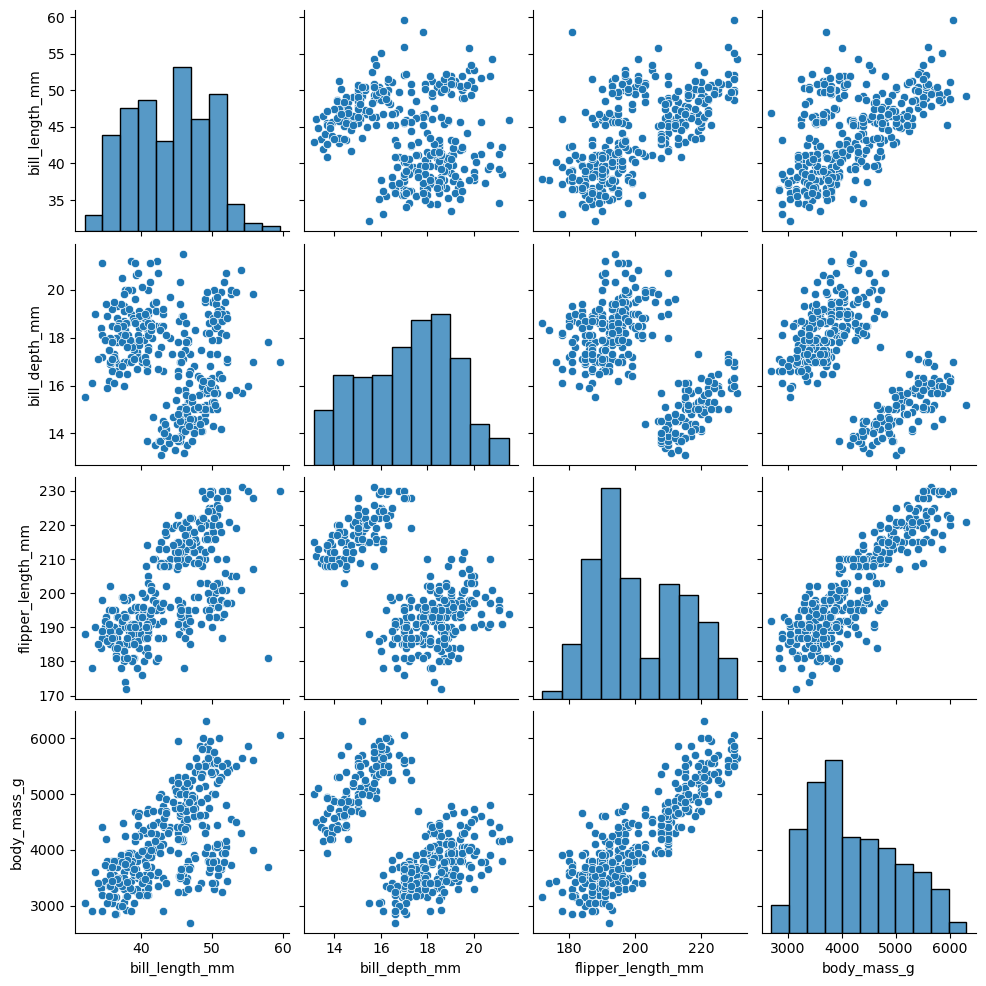

In [3]:
# Create pairwise scatterplots of Chinstrap penguins data - you run a scatterplot on the whole dataset
import seaborn as sns
sns.pairplot(penguins)

#First, extract the one X variable, bill_depth_mm, and the one Y variable, flipper_length_mm, that you are targeting.

In [27]:
# Subset Data
ols_data = penguins[["body_mass_g", "flipper_length_mm"]]

Because this example is using statsmodels, save the ordinary least squares formula as a string so the computer can understand how to run the regression. The Y variable, flipper_length_mm comes first, followed by a tilde and the name for the X variable, bill_depth_mm.


In [41]:
# Write out formula  = Y~X
ols_formula = "flipper_length_mm ~ body_mass_g"

**Construct the model**

In order to construct the model, you’ll first need to import the ols function from the statsmodels.formula.api interface.

Next, plug in the formula and the saved data into the ols function. Then, use the fit method to fit the model to the data. Lastly, use the summary method to get the results from the regression model. 

In [43]:
# Import ols function
from statsmodels.formula.api import ols
# Build OLS, fit model to data
OLS = ols(formula = ols_formula, data = ols_data)
model = OLS.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      flipper_length_mm   R-squared:                       0.762
Model:                            OLS   Adj. R-squared:                  0.761
Method:                 Least Squares   F-statistic:                     1060.
Date:                Tue, 01 Sep 2026   Prob (F-statistic):          3.13e-105
Time:                        14:27:44   Log-Likelihood:                -1112.1
No. Observations:                 333   AIC:                             2228.
Df Residuals:                     331   BIC:                             2236.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     137.0396      1.999     68.562      0.000     133.108     140.972
body_mass_g     0.0152      0.000     32.562      0.000       0.014       0.016
==============================================================================
Omnibus:                       11.941   Durbin-Watson:                   1.641
Prob(Omnibus):                  0.003   Jarque-Bera (JB):               12.696
Skew:                          -0.474   Prob(JB):                      0.00175
Kurtosis:                       2.872   Cond. No.                     2.28e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.28e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Let’s use the results of the regression model to translate the statistical findings for stakeholders. The interpretation of a regression model primarily depends on the coefficients and p-values. Coefficients indicate how changes in the independent variable (body_mass_g) are associated with changes in the dependent variable (flipper_length_mm). P-values demonstrate whether these coefficients are statistically significant.

In this case, the slope (coefficient for body_mass_g) is 0.0152, and the intercept is 137.0396. This means that flipper_length_mm equals the intercept (137.0396) plus the slope (0.0152) times body_mass_g. In other words, for every one-gram increase in body mass, we expect the flipper length to increase by approximately 0.0152 millimeters.

Next, let’s review the p-value associated with the coefficient for body mass, which is 0.000. This p-value tests the null hypothesis that the coefficient is zero. A small p-value (typically less than 0.05) suggests that the null hypothesis is likely false, meaning we reject the null hypothesis and conclude that the coefficient is statistically significantly different from zero. This indicates a strong relationship between body mass and flipper length.

However, it’s important to understand that the observed positive correlation between body mass and flipper length does not necessarily imply causation. Correlation refers to a relationship between two variables, but it doesn’t prove that one variable directly causes the other to change. The positive correlation observed could be influenced by various factors, and without further analysis, we cannot definitively say that changes in body mass cause changes in flipper length.


The confidence interval for the slope, ranging from 0.014 to 0.016, tells us that we can be 95% confident that the true effect of body mass on flipper length lies within this range. In other words, if we were to repeat this study many times, 95% of the calculated intervals would contain the true slope. 